In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/data-analysis-competition-lhc-for-ict-mu-students/File paths.txt
/kaggle/input/competitions/data-analysis-competition-lhc-for-ict-mu-students/Question.pdf


In [2]:
file_path = "/kaggle/input/competitions/data-analysis-competition-lhc-for-ict-mu-students/File paths.txt"

with open(file_path, "r") as file:
    print(file.read())

******* Path of CSV files*********************

dataset-20210607T020316Z-001\dataset\postLinks.csv
dataset-20210607T020316Z-001\dataset\posts_long.csv
dataset-20210607T020316Z-001\dataset\posts_short.csv

dataset-20210607T020316Z-002\dataset\users.csv

dataset-20210607T020316Z-003\dataset\post_history

******** Path of Json file*******************

dataset-20210607T020316Z-001\dataset\postLinks.json

dataset-20210607T020316Z-002\dataset\posts_long.json


In [3]:
!pip install -q gdown
!gdown "https://drive.google.com/uc?id=1eHChVwaAwG66p9eDhISOROPIvKXnMg9W" -O /kaggle/working/dataset.zip

Downloading...
From (original): https://drive.google.com/uc?id=1eHChVwaAwG66p9eDhISOROPIvKXnMg9W
From (redirected): https://drive.google.com/uc?id=1eHChVwaAwG66p9eDhISOROPIvKXnMg9W&confirm=t&uuid=5c75f9b8-b217-45dd-8233-a7438d0911a7
To: /kaggle/working/dataset.zip
100%|███████████████████████████████████████| 1.67G/1.67G [00:13<00:00, 124MB/s]


In [4]:
import zipfile
import os

zip_path = "/kaggle/working/dataset.zip"
extract_path = "/kaggle/working/dataset"

with zipfile.ZipFile(zip_path, 'r') as z:
    print("Total files:", len(z.namelist()))
    z.extractall(extract_path)

print("Extraction completed!")
print("Main folders:", os.listdir(extract_path))

Total files: 3
Extraction completed!
Main folders: ['Arjun_Assignment_data']


In [5]:
import os

base_path = "/kaggle/working/dataset/Arjun_Assignment_data"

for root, dirs, files in os.walk(base_path):
    print("\nFolder:", root)
    for file in files:
        print("  ", file)


Folder: /kaggle/working/dataset/Arjun_Assignment_data
   dataset-20210607T020316Z-002.zip
   dataset-20210607T020316Z-003.zip
   dataset-20210607T020316Z-001.zip


In [6]:
import zipfile
import os

base_path = "/kaggle/working/dataset/Arjun_Assignment_data"

for file in os.listdir(base_path):
    if file.endswith(".zip"):
        zip_path = os.path.join(base_path, file)
        extract_path = os.path.join(base_path, file[:-4])

        print("Extracting:", file)

        with zipfile.ZipFile(zip_path, 'r') as z:
            z.extractall(extract_path)

        print("Done:", extract_path)

print("All ZIP files extracted!")

Extracting: dataset-20210607T020316Z-002.zip
Done: /kaggle/working/dataset/Arjun_Assignment_data/dataset-20210607T020316Z-002
Extracting: dataset-20210607T020316Z-003.zip
Done: /kaggle/working/dataset/Arjun_Assignment_data/dataset-20210607T020316Z-003
Extracting: dataset-20210607T020316Z-001.zip
Done: /kaggle/working/dataset/Arjun_Assignment_data/dataset-20210607T020316Z-001
All ZIP files extracted!


In [7]:
for root, dirs, files in os.walk(base_path):
    for file in files:
        if file.endswith((".csv", ".json")):
            print(os.path.join(root, file))

/kaggle/working/dataset/Arjun_Assignment_data/dataset-20210607T020316Z-001/dataset/posts_short.csv
/kaggle/working/dataset/Arjun_Assignment_data/dataset-20210607T020316Z-001/dataset/postLinks.json
/kaggle/working/dataset/Arjun_Assignment_data/dataset-20210607T020316Z-001/dataset/postLinks.csv
/kaggle/working/dataset/Arjun_Assignment_data/dataset-20210607T020316Z-001/dataset/posts_long.csv
/kaggle/working/dataset/Arjun_Assignment_data/dataset-20210607T020316Z-003/dataset/post_history.csv
/kaggle/working/dataset/Arjun_Assignment_data/dataset-20210607T020316Z-002/dataset/posts_long.json
/kaggle/working/dataset/Arjun_Assignment_data/dataset-20210607T020316Z-002/dataset/users.csv


In [8]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

base_path = "/kaggle/working/dataset/Arjun_Assignment_data"

files = [
    "dataset-20210607T020316Z-002/dataset/users.csv",
    "dataset-20210607T020316Z-002/dataset/posts_long.json",
    "dataset-20210607T020316Z-003/dataset/post_history.csv",
    "dataset-20210607T020316Z-001/dataset/postLinks.json",
    "dataset-20210607T020316Z-001/dataset/posts_short.csv",
    "dataset-20210607T020316Z-001/dataset/posts_long.csv",
    "dataset-20210607T020316Z-001/dataset/postLinks.csv"
]

for file in files:
    path = os.path.join(base_path, file)
    
    print("\nFILE:", os.path.basename(path))
    
    if file.endswith(".csv"):
        df = pd.read_csv(path)
    else:
        df = pd.read_json(path)
    
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])
    
    print("\nSCHEMA:")
    print(df.info())
    
    print("\nCOLUMN NAMES:")
    print(df.columns.tolist())
    
    print("\nFIRST 2 ROWS:")
    display(df.head(2))


FILE: users.csv
Rows: 9321924
Columns: 9

SCHEMA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9321924 entries, 0 to 9321923
Data columns (total 9 columns):
 #   Column         Dtype 
---  ------         ----- 
 0   Unnamed: 0     int64 
 1   id             int64 
 2   reputation     int64 
 3   creation_date  object
 4   display_name   object
 5   views          int64 
 6   upvotes        int64 
 7   downvotes      int64 
 8   account_id     int64 
dtypes: int64(7), object(2)
memory usage: 640.1+ MB
None

COLUMN NAMES:
['Unnamed: 0', 'id', 'reputation', 'creation_date', 'display_name', 'views', 'upvotes', 'downvotes', 'account_id']

FIRST 2 ROWS:


,Unnamed: 0,id,reputation,creation_date,display_name,views,upvotes,downvotes,account_id
0,0,-1,1,2008-07-31T00:00:00.000,Community,649,274835,980920,-1
1,1,1,44300,2008-07-31T14:22:31.287,Jeff Atwood,408587,3367,1309,1



FILE: posts_long.json
Rows: 676204
Columns: 15

SCHEMA:
<class 'pandas.core.frame.DataFrame'>
Index: 676204 entries, 0 to 676203
Data columns (total 15 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   id                    676204 non-null  int64 
 1   post_type_id          676204 non-null  int64 
 2   accepted_answer_id    676204 non-null  int64 
 3   parent_id             676204 non-null  int64 
 4   creation_date         676204 non-null  object
 5   score                 676204 non-null  int64 
 6   view_count            676204 non-null  int64 
 7   owner_user_id         676204 non-null  int64 
 8   tags                  676204 non-null  object
 9   answer_count          676204 non-null  int64 
 10  comment_count         676204 non-null  int64 
 11  favorite_count        676204 non-null  int64 
 12  community_owned_date  1339 non-null    object
 13  title                 676204 non-null  object
 14  body            

,id,post_type_id,accepted_answer_id,parent_id,creation_date,score,view_count,owner_user_id,tags,answer_count,comment_count,favorite_count,community_owned_date,title,body
0,4,1,7,-999,2008-07-31T21:42:52.667,573,37080,8,<c#><floating-point><type-conversion><double><...,13,1,41,2012-10-31T16:42:47.213,Convert Decimal to Double?,<p>I want to use a track-bar to change a form'...
1,6,1,31,-999,2008-07-31T22:08:08.620,256,16306,9,<html><css><css3><internet-explorer-7>,5,0,10,None,Percentage width child element in absolutely p...,<p>I have an absolutely positioned <code>div</...



FILE: post_history.csv
Rows: 3641001
Columns: 10

SCHEMA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3641001 entries, 0 to 3641000
Data columns (total 10 columns):
 #   Column             Dtype 
---  ------             ----- 
 0   Unnamed: 0         int64 
 1   id                 int64 
 2   ph_type_id         int64 
 3   post_id            int64 
 4   revision_guid      object
 5   creation_date      object
 6   user_id            int64 
 7   user_display_name  object
 8   comment            object
 9   text               object
dtypes: int64(5), object(5)
memory usage: 277.8+ MB
None

COLUMN NAMES:
['Unnamed: 0', 'id', 'ph_type_id', 'post_id', 'revision_guid', 'creation_date', 'user_id', 'user_display_name', 'comment', 'text']

FIRST 2 ROWS:


...

/tmp/ipykernel_124/2804482833.py:24: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


Rows: 676204
Columns: 16

SCHEMA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 676204 entries, 0 to 676203
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   Unnamed: 0            676204 non-null  int64 
 1   id                    676204 non-null  int64 
 2   post_type_id          676204 non-null  int64 
 3   accepted_answer_id    676204 non-null  int64 
 4   parent_id             676204 non-null  int64 
 5   creation_date         676204 non-null  object
 6   score                 676204 non-null  int64 
 7   view_count            676204 non-null  int64 
 8   owner_user_id         676204 non-null  int64 
 9   tags                  676204 non-null  object
 10  answer_count          676204 non-null  int64 
 11  comment_count         676204 non-null  int64 
 12  favorite_count        676204 non-null  int64 
 13  community_owned_date  1339 non-null    object
 14  title                 676204 non-n

,Unnamed: 0,id,post_type_id,accepted_answer_id,parent_id,creation_date,score,view_count,owner_user_id,tags,answer_count,comment_count,favorite_count,community_owned_date,title,body
0,0,4,1,7,-999,2008-07-31T21:42:52.667,573,37080,8,<c#><floating-point><type-conversion><double><...,13,1,41,2012-10-31T16:42:47.213,Convert Decimal to Double?,<p>I want to use a track-bar to change a form'...
1,1,6,1,31,-999,2008-07-31T22:08:08.620,256,16306,9,<html><css><css3><internet-explorer-7>,5,0,10,NaN,Percentage width child element in absolutely p...,<p>I have an absolutely positioned <code>div</...



FILE: postLinks.csv
Rows: 5292624
Columns: 6

SCHEMA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5292624 entries, 0 to 5292623
Data columns (total 6 columns):
 #   Column           Dtype 
---  ------           ----- 
 0   Unnamed: 0       int64 
 1   id               int64 
 2   creation_date    object
 3   post_id          int64 
 4   related_post_id  int64 
 5   link_type_id     int64 
dtypes: int64(5), object(1)
memory usage: 242.3+ MB
None

COLUMN NAMES:
['Unnamed: 0', 'id', 'creation_date', 'post_id', 'related_post_id', 'link_type_id']

FIRST 2 ROWS:


,Unnamed: 0,id,creation_date,post_id,related_post_id,link_type_id
0,0,19,2010-04-26T02:59:48.130,109,32412,1
1,1,37,2010-04-26T02:59:48.600,1970,617600,1


Qn 1. Determine the Number of Tags Per Question

In [9]:
posts = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-001/dataset/posts_short.csv",
    nrows=5
)

print(posts.columns.tolist())
display(posts.head())

['Unnamed: 0', 'id', 'post_type_id', 'accepted_answer_id', 'parent_id', 'creation_date', 'score', 'view_count', 'owner_user_id', 'tags', 'answer_count', 'comment_count', 'favorite_count', 'community_owned_date']


,Unnamed: 0,id,post_type_id,accepted_answer_id,parent_id,creation_date,score,view_count,owner_user_id,tags,answer_count,comment_count,favorite_count,community_owned_date
0,0,4,1,7,-999,2008-07-31T21:42:52.667,573,37080,8,<c#><floating-point><type-conversion><double><...,13,1,41,2012-10-31T16:42:47.213
1,1,6,1,31,-999,2008-07-31T22:08:08.620,256,16306,9,<html><css><css3><internet-explorer-7>,5,0,10,NaN
2,2,9,1,1404,-999,2008-07-31T23:40:59.743,1743,480476,1,<c#><.net><datetime>,64,7,399,2011-08-16T19:40:43.080
3,3,11,1,1248,-999,2008-07-31T23:55:37.967,1348,136033,1,<c#><datetime><time><datediff><relative-time-s...,35,3,529,2009-09-04T13:15:59.820
4,4,13,1,-999,-999,2008-08-01T00:42:38.903,539,157009,9,<javascript><html><browser><timezone><timezone...,25,6,137,NaN


In [10]:
posts = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-001/dataset/posts_short.csv",
    usecols=["post_type_id", "tags"]
)

questions = posts[posts["post_type_id"] == 1]

tag_count = questions["tags"].fillna("").str.count("<")

print("Total questions:", len(questions))
print("Total tags across all questions:", tag_count.sum())
print("Average tags per question:", tag_count.mean())

print("\nNumber of questions for each tag count:")
display(tag_count.value_counts().sort_index().rename_axis("Number of tags").reset_index(name="Number of questions"))

Total questions: 676204
Total tags across all questions: 1921047
Average tags per question: 2.840928181436371

Number of questions for each tag count:


,Number of tags,Number of questions
0,1,94523
1,2,189704
2,3,194334
3,4,124127
4,5,73490
5,6,26


Qn 2. Determine the Total Number of Unique Tags

In [11]:
posts = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-001/dataset/posts_short.csv",
    usecols=["post_type_id", "tags"]
)

questions = posts[posts["post_type_id"] == 1]

all_tags = questions["tags"].dropna().str.findall(r"<([^<>]+)>")
unique_tags = set(tag for tags in all_tags for tag in tags)

print("Total number of unique tags:", len(unique_tags))

Total number of unique tags: 25310


Qn 3. Determine the top-25 Tags appearing frequently

In [12]:
posts = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-001/dataset/posts_short.csv",
    usecols=["post_type_id", "tags"]
)

questions = posts[posts["post_type_id"] == 1]

tag_counts = (
    questions["tags"]
    .dropna()
    .str.findall(r"<([^<>]+)>")
    .explode()
    .value_counts()
)

top_25_tags = tag_counts.head(25)

print("Top 25 most frequent tags:")
display(top_25_tags.rename_axis("Tag").reset_index(name="Frequency"))

Top 25 most frequent tags:


,Tag,Frequency
0,java,94846
1,javascript,81346
2,php,65333
3,c#,61899
4,python,61505
5,c++,40158
6,android,39910
7,html,33736
8,jquery,32601
9,mysql,24765


Qn 4. Determine the nature of the distribution of top-500 tags

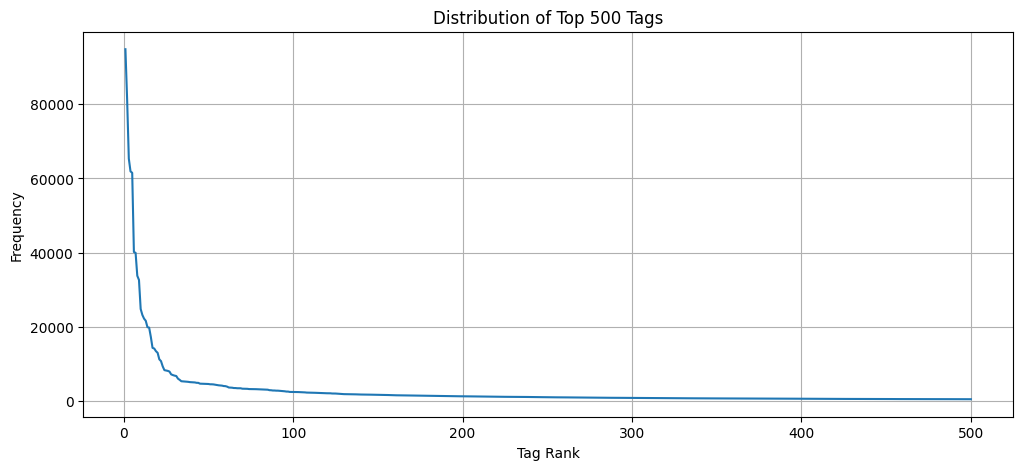

In [13]:
import matplotlib.pyplot as plt

# Get the top 500 tags
top_500_tags = tag_counts.head(500)

# Plot the distribution
plt.figure(figsize=(12, 5))
plt.plot(range(1, 501), top_500_tags.values)

plt.title("Distribution of Top 500 Tags")
plt.xlabel("Tag Rank")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

Qn 5. Determine the ratio of duplicate questions asked in each month
For the given dataset, generate a line graph as follows. You need to consider the
time between 2008 and 2018.

All above for 5 were js to check, not needed

In [14]:
postlinks = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-001/dataset/postLinks.csv"
)

print(postlinks.columns.tolist())

['Unnamed: 0', 'id', 'creation_date', 'post_id', 'related_post_id', 'link_type_id']


,month,total_questions,duplicate_questions,Duplicate Ratio (%)
0,2008-07,4,0,0.000000
1,2008-08,816,30,3.676471
2,2008-09,2399,120,5.002084
3,2008-10,2111,117,5.542397
4,2008-11,1581,118,7.463631
...,...,...,...,...
118,2018-05,8172,7565,92.572198
119,2018-06,7280,6795,93.337912
120,2018-07,7332,6908,94.217130
121,2018-08,9227,8910,96.564430


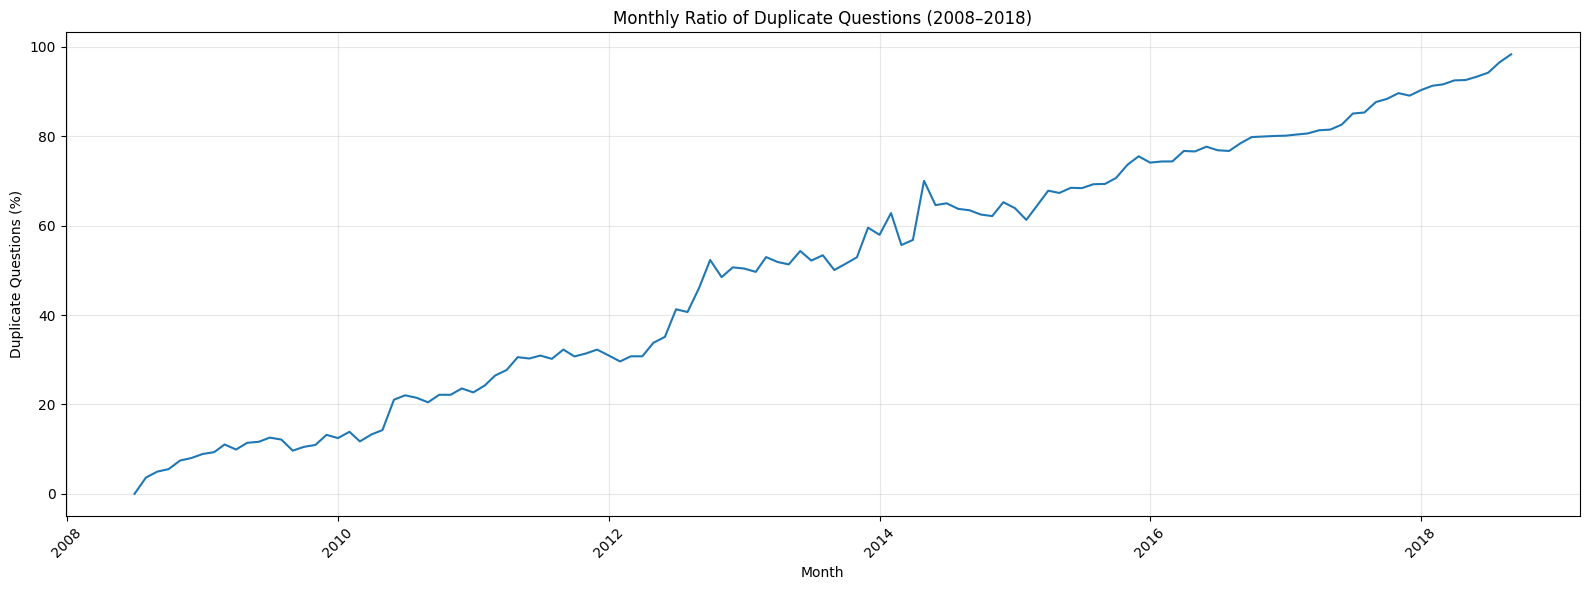

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Load post links
postlinks = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-001/dataset/postLinks.csv"
)

# Load questions
questions = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-001/dataset/posts_long.csv",
    usecols=["id", "post_type_id", "creation_date"]
)

# Keep questions only
questions = questions[questions["post_type_id"] == 1].copy()
questions["creation_date"] = pd.to_datetime(
    questions["creation_date"], errors="coerce"
)

# Identify duplicate questions using LinkTypeId = 3
duplicate_question_ids = set(
    postlinks.loc[postlinks["link_type_id"] == 3, "post_id"].dropna()
)

questions["is_duplicate"] = questions["id"].isin(duplicate_question_ids)

# Select questions from 2008 to 2018
q = questions[
    (questions["creation_date"] >= "2008-01-01") &
    (questions["creation_date"] < "2019-01-01")
].copy()

q["month"] = q["creation_date"].dt.to_period("M")

# Calculate monthly ratio
monthly_data = q.groupby("month").agg(
    total_questions=("id", "count"),
    duplicate_questions=("is_duplicate", "sum")
)

monthly_data["Duplicate Ratio (%)"] = (
    monthly_data["duplicate_questions"] /
    monthly_data["total_questions"] * 100
)

# Display monthly ratios
display(monthly_data.reset_index())

# Plot graph
plt.figure(figsize=(16, 6))
plt.plot(
    monthly_data.index.to_timestamp(),
    monthly_data["Duplicate Ratio (%)"]
)

plt.title("Monthly Ratio of Duplicate Questions (2008–2018)")
plt.xlabel("Month")
plt.ylabel("Duplicate Questions (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Qn 6. Determine the percentage of duplicate questions associated with different tags

Top 20 Tags by Duplicate Question Percentage


,Tag,Total Questions,Duplicate Questions,Duplicate Percentage
3621,nullreferenceexception,505,475,94.06
223,nullpointerexception,2373,2122,89.42
21303,python-3.6,183,152,83.06
16216,jsf-2.2,211,174,82.46
5494,contact,106,87,82.08
6524,server,342,277,80.99
8309,mariadb,156,126,80.77
4280,indexoutofboundsexception,290,234,80.69
1833,frontend,136,109,80.15
433,mysqli,3050,2439,79.97


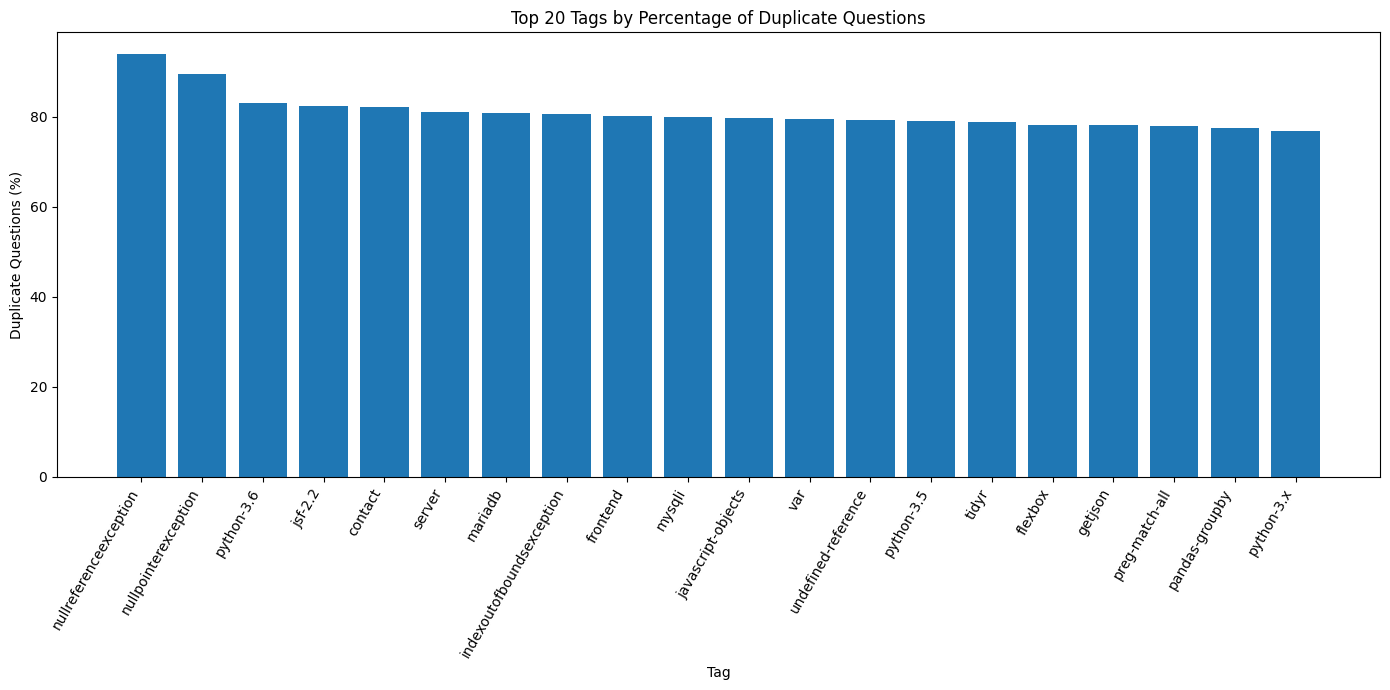

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import re

# Load data
base_path = "/kaggle/working/dataset/Arjun_Assignment_data"

questions = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-001/dataset/posts_short.csv",
    low_memory=False
)

postlinks = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-001/dataset/postLinks.csv"
)

# Keep questions only
questions = questions[questions["post_type_id"] == 1].copy()

# Identify duplicate question IDs
duplicate_question_ids = set(
    postlinks.loc[
        postlinks["link_type_id"] == 3, "post_id"
    ].dropna()
)

questions["is_duplicate"] = questions["id"].isin(
    duplicate_question_ids
)

# Count total and duplicate questions for each tag
tag_total = {}
tag_duplicate = {}

for _, row in questions[["id", "tags", "is_duplicate"]].iterrows():

    if pd.isna(row["tags"]):
        continue

    tags = set(re.findall(r"<([^>]+)>", row["tags"]))

    for tag in tags:
        tag_total[tag] = tag_total.get(tag, 0) + 1

        if row["is_duplicate"]:
            tag_duplicate[tag] = tag_duplicate.get(tag, 0) + 1

# Create results table
tag_result = pd.DataFrame([
    {
        "Tag": tag,
        "Total Questions": total,
        "Duplicate Questions": tag_duplicate.get(tag, 0),
        "Duplicate Percentage": (
            tag_duplicate.get(tag, 0) / total * 100
        )
    }
    for tag, total in tag_total.items()
])

# Exclude tags appearing in fewer than 100 questions
meaningful_tags = tag_result[
    tag_result["Total Questions"] >= 100
].copy()

# Select top 20 tags by duplicate percentage
top20 = meaningful_tags.sort_values(
    "Duplicate Percentage", ascending=False
).head(20)

print("Top 20 Tags by Duplicate Question Percentage")
display(top20.round(2))

# Plot bar chart
plt.figure(figsize=(14, 7))
plt.bar(top20["Tag"], top20["Duplicate Percentage"])

plt.xlabel("Tag")
plt.ylabel("Duplicate Questions (%)")
plt.title("Top 20 Tags by Percentage of Duplicate Questions")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


Qn 7. Determine the time required to close duplicate questions
You need to generate a bar chart

Duplicate questions with valid closure times: 399973


,Number of Questions
closure_time_group,
Under 1 hour,182903
1–24 hours,133035
1–7 days,30123
1–30 days,8454
1–12 months,18190
Over 1 year,27268


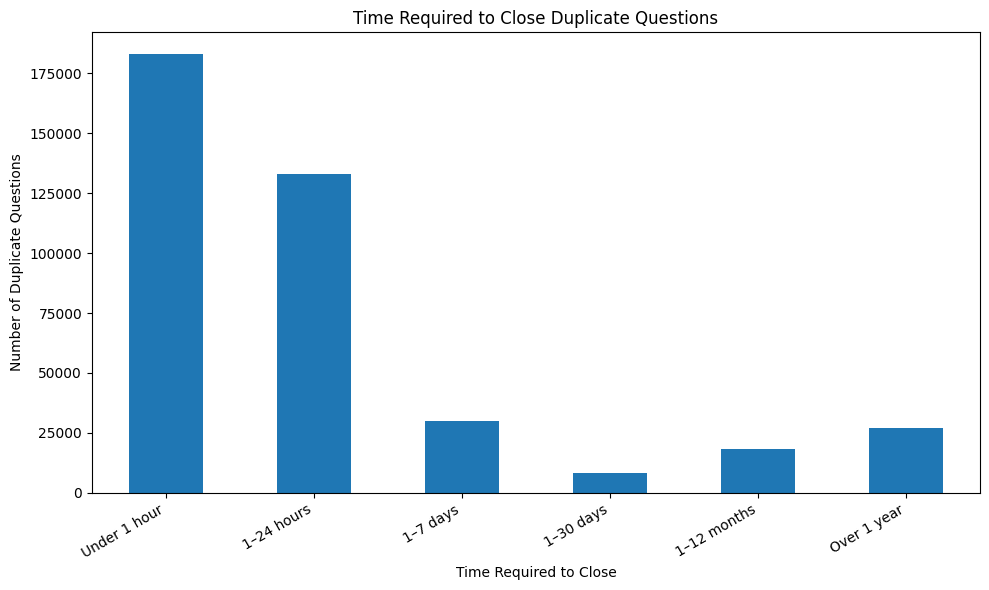

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import json

# Load data
history = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-003/dataset/post_history.csv",
    low_memory=False
)

postlinks = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-001/dataset/postLinks.csv"
)

questions = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-001/dataset/posts_long.csv",
    low_memory=False
)

# Identify duplicate question IDs
duplicate_ids = set(
    postlinks.loc[
        postlinks["link_type_id"] == 3, "post_id"
    ].dropna()
)

# Keep only duplicate questions
questions = questions[
    (questions["post_type_id"] == 1) &
    (questions["id"].isin(duplicate_ids))
].copy()

questions["creation_date"] = pd.to_datetime(
    questions["creation_date"], errors="coerce"
)

# Get closure history records (ph_type_id = 10)
closed = history[history["ph_type_id"] == 10].copy()
closed["creation_date"] = pd.to_datetime(
    closed["creation_date"], errors="coerce"
)

# Keep closure records linked to duplicate questions
closed = closed[closed["post_id"].isin(duplicate_ids)]

# First closure event for each duplicate question
closed = closed.sort_values("creation_date").drop_duplicates(
    subset="post_id", keep="first"
)

# Calculate closure time
merged = questions[["id", "creation_date"]].merge(
    closed[["post_id", "creation_date"]],
    left_on="id",
    right_on="post_id",
    suffixes=("_question", "_closed")
)

merged["hours_to_close"] = (
    merged["creation_date_closed"] -
    merged["creation_date_question"]
).dt.total_seconds() / 3600

# Remove invalid time differences
merged = merged[
    merged["hours_to_close"].notna() &
    (merged["hours_to_close"] >= 0)
].copy()

# Group closure times
bins = [0, 1, 24, 24*7, 24*30, 24*365, float("inf")]
labels = [
    "Under 1 hour",
    "1–24 hours",
    "1–7 days",
    "1–30 days",
    "1–12 months",
    "Over 1 year"
]

merged["closure_time_group"] = pd.cut(
    merged["hours_to_close"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

time_counts = merged["closure_time_group"].value_counts(
    sort=False
)

print("Duplicate questions with valid closure times:", len(merged))
display(time_counts.rename("Number of Questions").to_frame())

# Bar chart
time_counts.plot(kind="bar", figsize=(10, 6))

plt.xlabel("Time Required to Close")
plt.ylabel("Number of Duplicate Questions")
plt.title("Time Required to Close Duplicate Questions")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


Qn 8. Distribution of the reputation of users whose questions are closed as
duplicates

,Number of Users
reputation_category,
0–1,32959
2–100,139627
101–500,53682
501–1K,20785
1K–5K,27598
5K–10K,5228
10K–50K,4096
Above 50K,636


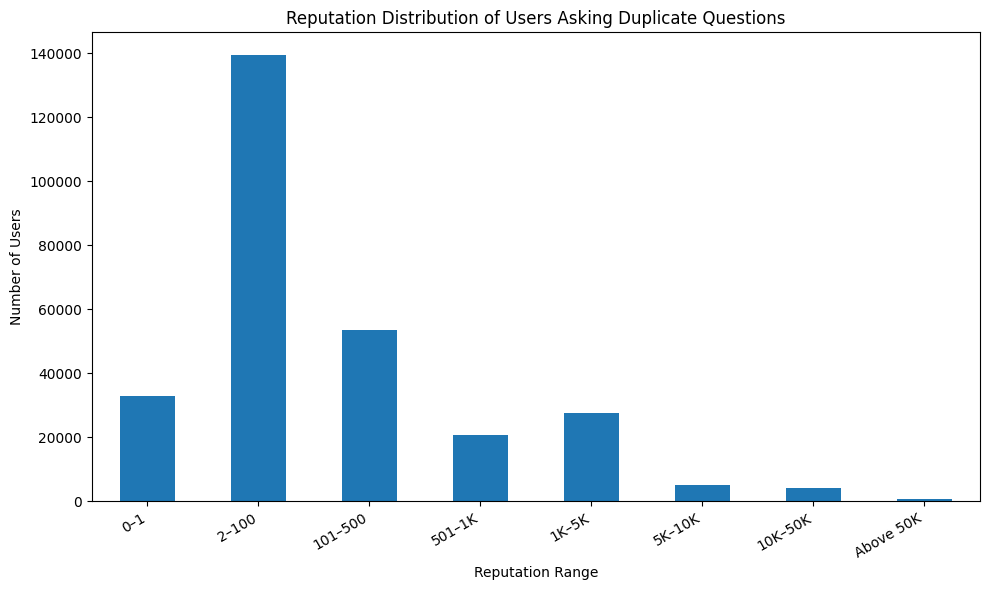

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# Load datasets
users = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-002/dataset/users.csv",
    low_memory=False
)

postlinks = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-001/dataset/postLinks.csv"
)

posts = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-001/dataset/posts_long.csv",
    low_memory=False
)

# Get duplicate question IDs
duplicate_links = postlinks[postlinks["link_type_id"] == 3]
duplicate_ids = set(duplicate_links["post_id"].dropna())

# Find questions that are duplicates
duplicate_questions = posts[
    (posts["post_type_id"] == 1) &
    (posts["id"].isin(duplicate_ids))
].copy()

# Get the users who asked these questions
duplicate_questions["owner_user_id"] = pd.to_numeric(
    duplicate_questions["owner_user_id"], errors="coerce"
)

user_ids = duplicate_questions["owner_user_id"].dropna().unique()

# Get reputation of these users
users["id"] = pd.to_numeric(users["id"], errors="coerce")
users["reputation"] = pd.to_numeric(users["reputation"], errors="coerce")

duplicate_users = users[users["id"].isin(user_ids)].copy()
duplicate_users = duplicate_users.dropna(subset=["reputation"])

# Group users by reputation
bins = [-1, 1, 100, 500, 1000, 5000, 10000, 50000, float("inf")]

labels = [
    "0–1", "2–100", "101–500", "501–1K",
    "1K–5K", "5K–10K", "10K–50K", "Above 50K"
]

duplicate_users["reputation_category"] = pd.cut(
    duplicate_users["reputation"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

reputation_counts = duplicate_users["reputation_category"].value_counts(
    sort=False
)

display(reputation_counts.rename("Number of Users").to_frame())

# Bar chart
reputation_counts.plot(kind="bar", figsize=(10, 6))

plt.xlabel("Reputation Range")
plt.ylabel("Number of Users")
plt.title("Reputation Distribution of Users Asking Duplicate Questions")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Qn 9. Consider the first 500 tags and determine how many percentage of questions
are been covered

In [21]:
import pandas as pd
import re

# Load posts
posts = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-001/dataset/posts_long.csv",
    low_memory=False
)

# Select questions only
questions = posts[posts["post_type_id"] == 1].copy()
questions = questions.dropna(subset=["tags"])

# Count frequency of each tag
tag_counts = {}

for tags in questions["tags"]:
    for tag in re.findall(r"<([^>]+)>", tags):
        tag_counts[tag] = tag_counts.get(tag, 0) + 1

# Get the 500 most frequent tags
top_500_tags = set(
    pd.Series(tag_counts).sort_values(ascending=False).head(500).index
)

# Count questions containing at least one top-500 tag
covered_questions = questions["tags"].apply(
    lambda tags: any(
        tag in top_500_tags
        for tag in re.findall(r"<([^>]+)>", tags)
    )
).sum()

total_questions = len(questions)
percentage = (covered_questions / total_questions) * 100

print("Total questions:", total_questions)
print("Questions covered by top 500 tags:", covered_questions)
print(f"Percentage of questions covered: {percentage:.2f}%")


Total questions: 676204
Questions covered by top 500 tags: 662549
Percentage of questions covered: 97.98%


Qn 10. Consider the first 5000 tags and determine how many percentage of questions
are been covered

In [22]:
import pandas as pd
import re

# Load posts
posts = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-001/dataset/posts_long.csv",
    low_memory=False
)

# Select questions only
questions = posts[posts["post_type_id"] == 1].copy()
questions = questions.dropna(subset=["tags"])

# Count frequency of each tag
tag_counts = {}

for tags in questions["tags"]:
    for tag in re.findall(r"<([^>]+)>", tags):
        tag_counts[tag] = tag_counts.get(tag, 0) + 1

# Get the 500 most frequent tags
top_5000_tags = set(
    pd.Series(tag_counts).sort_values(ascending=False).head(5000).index
)

# Count questions containing at least one top-5000 tag
covered_questions = questions["tags"].apply(
    lambda tags: any(
        tag in top_5000_tags
        for tag in re.findall(r"<([^>]+)>", tags)
    )
).sum()

total_questions = len(questions)
percentage = (covered_questions / total_questions) * 100

print("Total questions:", total_questions)
print("Questions covered by top 5000 tags:", covered_questions)
print(f"Percentage of questions covered: {percentage:.2f}%")


Total questions: 676204
Questions covered by top 5000 tags: 675144
Percentage of questions covered: 99.84%


11-15 on our own

Qn 11. What is the distribution of questions by post score?

,Number of Questions
score_range,
Negative,75869
Zero,231266
1–5,202322
6–10,45553
Above 10,121194


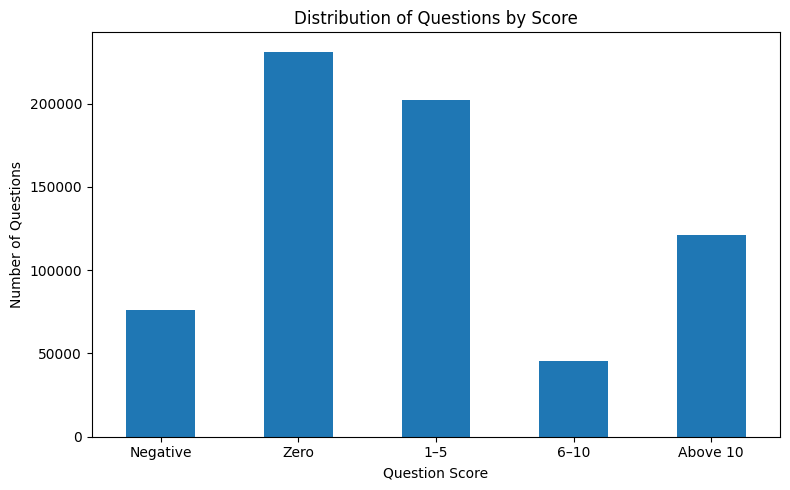

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

posts = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-001/dataset/posts_long.csv",
    low_memory=False
)

questions = posts[posts["post_type_id"] == 1].copy()
questions["score"] = pd.to_numeric(questions["score"], errors="coerce")
questions = questions.dropna(subset=["score"])

bins = [-float("inf"), -1, 0, 5, 10, float("inf")]
labels = ["Negative", "Zero", "1–5", "6–10", "Above 10"]

questions["score_range"] = pd.cut(
    questions["score"], bins=bins, labels=labels
)

counts = questions["score_range"].value_counts(sort=False)
display(counts.rename("Number of Questions").to_frame())

counts.plot(kind="bar", figsize=(8, 5))
plt.xlabel("Question Score")
plt.ylabel("Number of Questions")
plt.title("Distribution of Questions by Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Qn 12. Which years had the highest number of questions?

,Number of Questions
year,
2008,8308
2009,26141
2010,39683
2011,58404
2012,69149
2013,82366
2014,76322
2015,79091
2016,85194


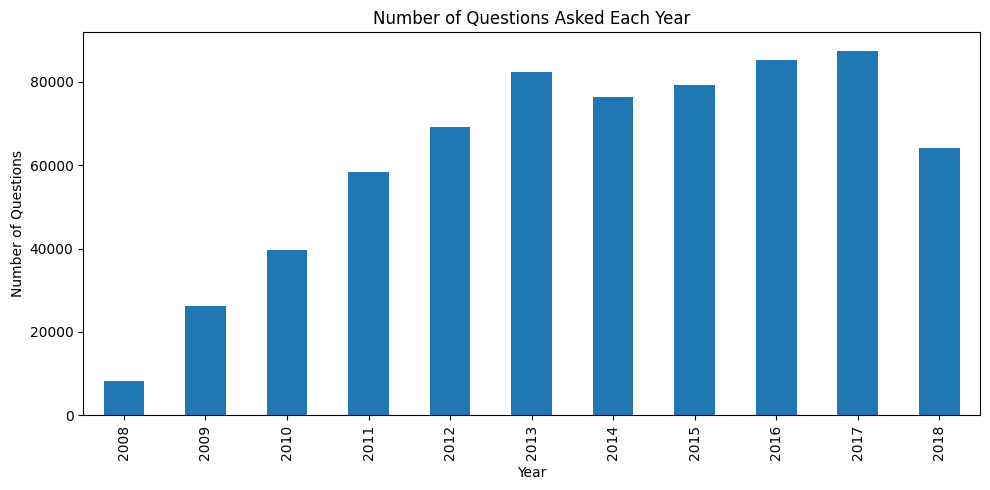

Year with the most questions: 2017
Number of questions: 87417


In [24]:
import pandas as pd
import matplotlib.pyplot as plt

posts = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-001/dataset/posts_long.csv",
    low_memory=False
)

questions = posts[posts["post_type_id"] == 1].copy()
questions["creation_date"] = pd.to_datetime(
    questions["creation_date"], errors="coerce"
)
questions = questions.dropna(subset=["creation_date"])

questions["year"] = questions["creation_date"].dt.year
year_counts = questions["year"].value_counts().sort_index()

display(year_counts.rename("Number of Questions").to_frame())

year_counts.plot(kind="bar", figsize=(10, 5))
plt.xlabel("Year")
plt.ylabel("Number of Questions")
plt.title("Number of Questions Asked Each Year")
plt.tight_layout()
plt.show()

print("Year with the most questions:", year_counts.idxmax())
print("Number of questions:", year_counts.max())


Qn 13. What is the relationship between question views and question scores?

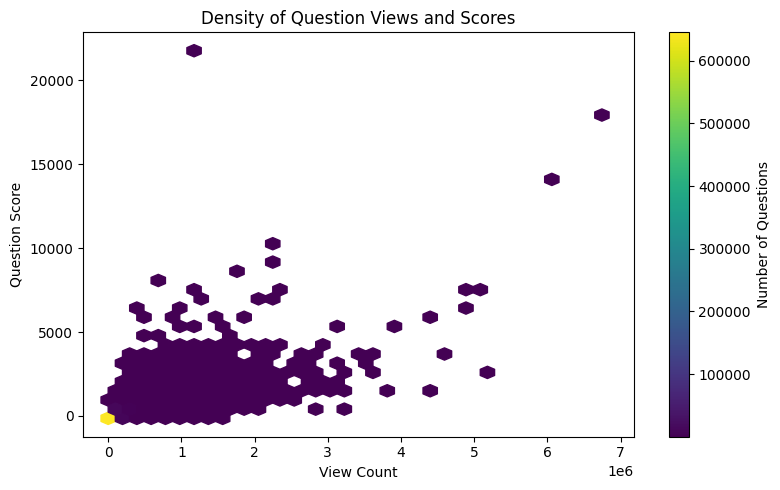

Correlation: 0.729


In [30]:
import pandas as pd
import matplotlib.pyplot as plt

posts = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-001/dataset/posts_long.csv",
    low_memory=False
)

questions = posts[posts["post_type_id"] == 1].copy()
questions["view_count"] = pd.to_numeric(questions["view_count"], errors="coerce")
questions["score"] = pd.to_numeric(questions["score"], errors="coerce")
questions = questions.dropna(subset=["view_count", "score"])
questions = questions[questions["view_count"] > 0]

plt.figure(figsize=(8, 5))
plt.hexbin(
    questions["view_count"],
    questions["score"],
    gridsize=35,
    mincnt=1
)
plt.colorbar(label="Number of Questions")
plt.xlabel("View Count")
plt.ylabel("Question Score")
plt.title("Density of Question Views and Scores")
plt.tight_layout()
plt.show()

print(
    "Correlation:",
    round(questions["view_count"].corr(questions["score"]), 3)
)


Qn 14. What percentage of questions receive at least one answer?

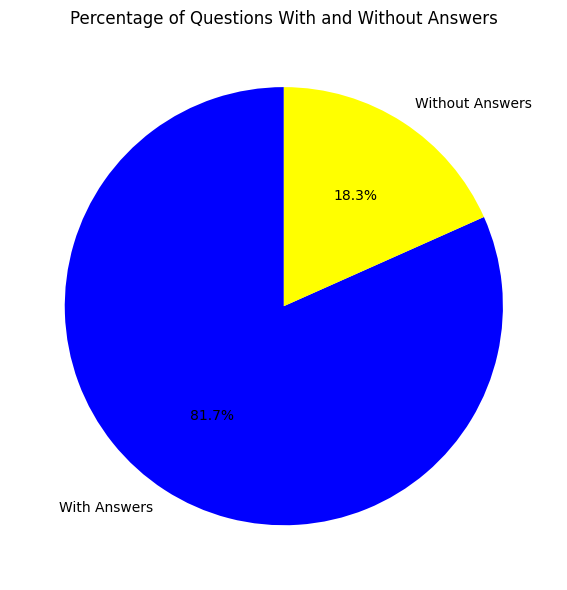

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

posts = pd.read_csv(
    base_path + "/dataset-20210607T020316Z-001/dataset/posts_long.csv",
    low_memory=False
)

questions = posts[posts["post_type_id"] == 1].copy()
questions["answer_count"] = pd.to_numeric(
    questions["answer_count"], errors="coerce"
)
questions = questions.dropna(subset=["answer_count"])

answered = (questions["answer_count"] > 0).sum()
unanswered = (questions["answer_count"] == 0).sum()

plt.figure(figsize=(6, 6))
plt.pie(
    [answered, unanswered],
    labels=["With Answers", "Without Answers"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["blue", "yellow"]
)
plt.title("Percentage of Questions With and Without Answers")
plt.tight_layout()
plt.show()


Qn 15. What is the relationship between question score and comment count?

Correlation between score and comment count: 0.034


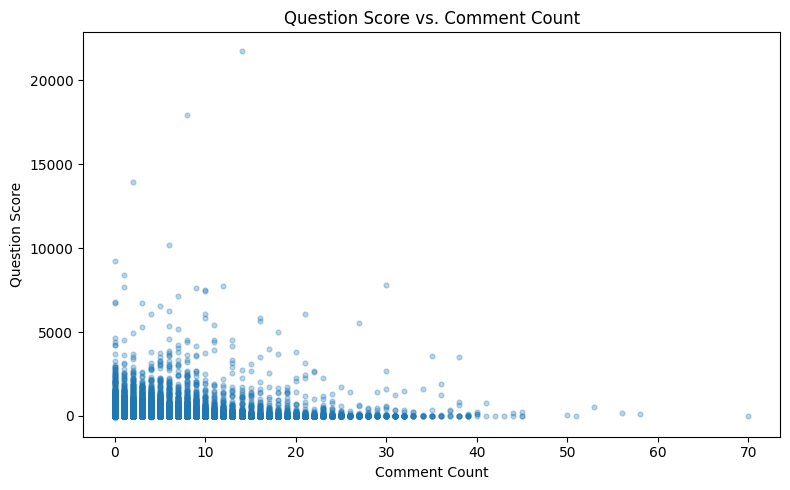

In [35]:
import pandas as pd
import matplotlib.pyplot as plt

path = base_path + "/dataset-20210607T020316Z-001/dataset/posts_long.csv"
posts = pd.read_csv(path, low_memory=False)

questions = posts[posts["post_type_id"] == 1].copy()

questions["score"] = pd.to_numeric(
    questions["score"], errors="coerce"
)
questions["comment_count"] = pd.to_numeric(
    questions["comment_count"], errors="coerce"
)

questions = questions.dropna(subset=["score", "comment_count"])

print(
    "Correlation between score and comment count:",
    round(questions["score"].corr(questions["comment_count"]), 3)
)

plt.figure(figsize=(8, 5))
plt.scatter(
    questions["comment_count"],
    questions["score"],
    alpha=0.3,
    s=12
)
plt.xlabel("Comment Count")
plt.ylabel("Question Score")
plt.title("Question Score vs. Comment Count")
plt.tight_layout()
plt.show()
